     Load and inspect your dataset

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("StudentPerformanceFactors.csv")

In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (6607, 20)


In [4]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


    Understand the columns and data types

In [5]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [6]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence             

    Check for missing values and duplicate rows

In [7]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Missing values in each column:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Total missing values: 235

Duplicate rows: 0


In [8]:
df.describe()


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


       Inspect data quality

In [9]:

# Check missing values in each column
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check the percentage of missing values
print("\nMissing value percentages:")
print((df.isnull().mean() * 100).round(2))

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check data types
print("\nColumn data types:")
print(df.dtypes)


Missing values:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Missing value percentages:
Hours_Studied                 0.00
Attendance                    0.00
Parental_Involvement          0.00
Access_to_Resources           0.00
Extracurricular_Activities    0.00
Sleep_Hours                   0.00
Previous_Scores               0.00
Motivation_Level              0.00
Internet_Access               0.00
Tutoring_Sessions             0.00
Family_Income                 0.00
Teacher_Quality               1.18
School_Type                   0.00
Peer_Influence                0.00
Physical_Activity             0.00
Learning_Disabilities         0.00
Parental_Education_Level      1.36
Distance_from_Home            1.01
Gender                        0.00
Exam_Score                    0.00
dtype: float64

Duplicate rows: 0

Column data types:
Hours_Studied                  int64
Attendance                     int64
Parental_Involvement  

     Clean your dataset

In [10]:

# Display the categories in columns with missing values
print("Teacher quality categories:")
print(df["Teacher_Quality"].value_counts(dropna=False))

print("\nParental education categories:")
print(df["Parental_Education_Level"].value_counts(dropna=False))

print("\nDistance from home categories:")
print(df["Distance_from_Home"].value_counts(dropna=False))

# Check exam score range
print("\nExam score statistics:")
print(df["Exam_Score"].describe())


Teacher quality categories:
Teacher_Quality
Medium    3925
High      1947
Low        657
NaN         78
Name: count, dtype: int64

Parental education categories:
Parental_Education_Level
High School     3223
College         1989
Postgraduate    1305
NaN               90
Name: count, dtype: int64

Distance from home categories:
Distance_from_Home
Near        3884
Moderate    1998
Far          658
NaN           67
Name: count, dtype: int64

Exam score statistics:
count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64


    copy of the dataset

In [11]:
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)


Original dataset shape: (6607, 20)
Working dataset shape: (6607, 20)


    Filling the missing categorical values

In [12]:
# Fill missing categorical values using the most frequent category
columns_to_fill = [
    "Teacher_Quality",
    "Parental_Education_Level",
    "Distance_from_Home"
]

for column in columns_to_fill:
    most_common = df_clean[column].mode()[0]
    df_clean[column] = df_clean[column].fillna(most_common)
    print(column, "filled with:", most_common)

# Check whether any missing values remain
print("\nTotal missing values after cleaning:",
      df_clean.isnull().sum().sum())


Teacher_Quality filled with: Medium
Parental_Education_Level filled with: High School
Distance_from_Home filled with: Near

Total missing values after cleaning: 0


    Verify the cleaning

In [13]:
print("Missing values by column:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nDuplicate rows:", df_clean.duplicated().sum())
print("Dataset shape after cleaning:", df_clean.shape)


Missing values by column:
Series([], dtype: int64)

Duplicate rows: 0
Dataset shape after cleaning: (6607, 20)


    Exploratory Data Analysis (EDA)

In [15]:
sns.set_theme(style="whitegrid")

Distribution of exam scores

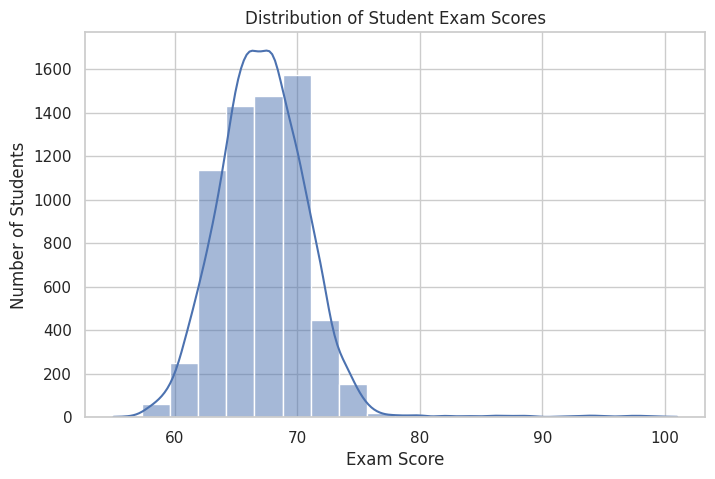

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_clean, x="Exam_Score", bins=20, kde=True)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()


Study hours versus exam score

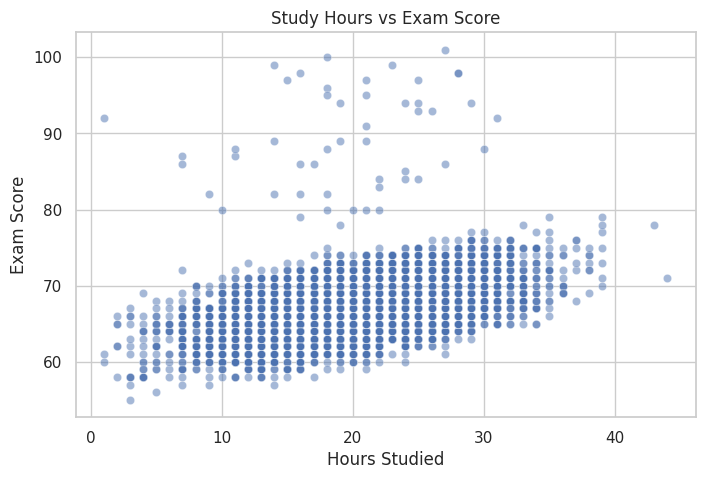

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Hours_Studied",
    y="Exam_Score",
    alpha=0.5
)

plt.title("Study Hours vs Exam Score")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")

plt.show()


Attendance versus exam score

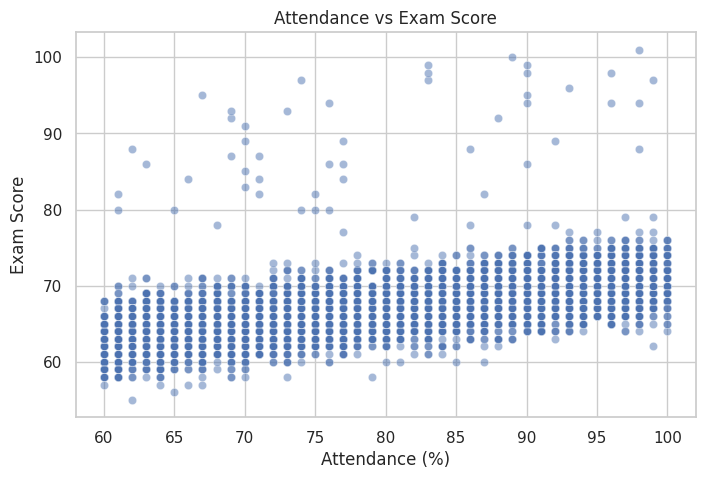

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Attendance",
    y="Exam_Score",
    alpha=0.5
)

plt.title("Attendance vs Exam Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")

plt.show()


    Average exam score by parental involvement

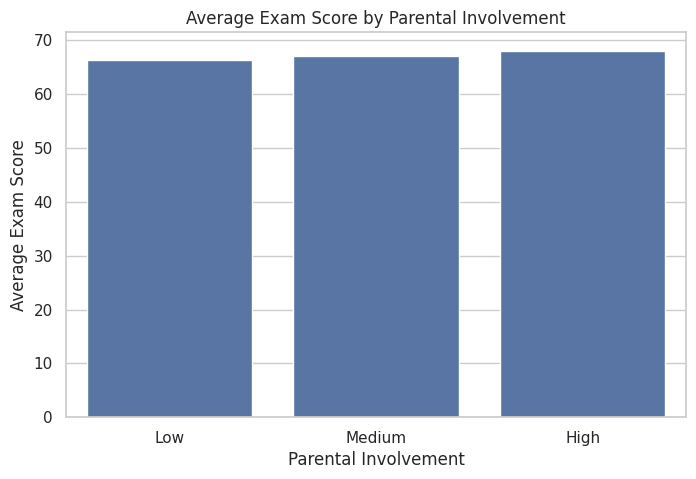

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="Parental_Involvement",
    y="Exam_Score",
    errorbar=None
)

plt.title("Average Exam Score by Parental Involvement")
plt.xlabel("Parental Involvement")
plt.ylabel("Average Exam Score")

plt.show()


    Correlation between numerical features

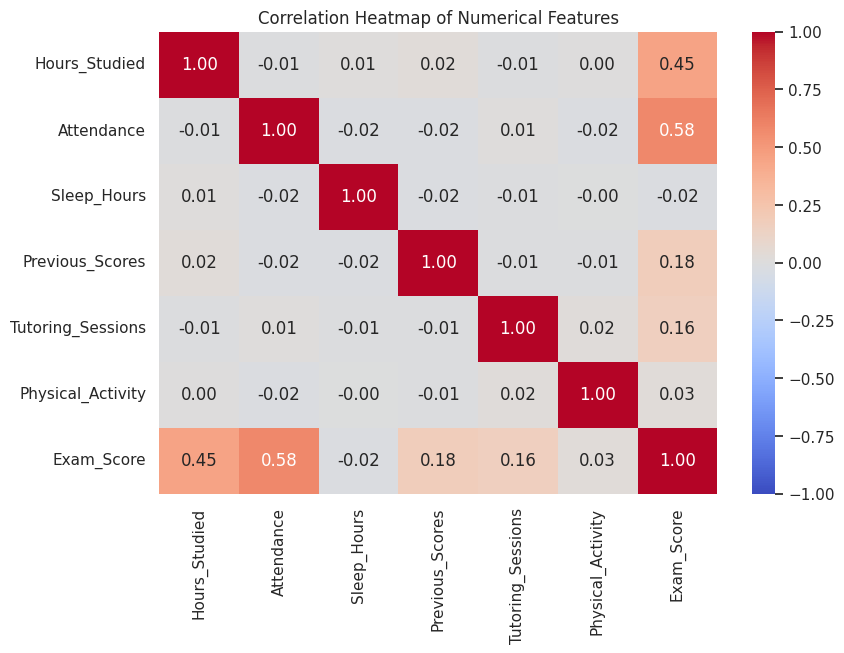

In [20]:

numeric_columns = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity",
    "Exam_Score"
]

correlation = df_clean[numeric_columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()


    Define the problem
o analyze student performance factors and build a Gradient Boosting Regression model that predicts students' exam scores based on their study habits, attendance, and other available factors.


Features (X): The information used to make predictions, such as study hours, attendance, and parental involvement.



Target (y): Exam_Score, the value we want the model to predict.

    Separate the features and target

In [21]:
# Input features: all columns except the target
X = df_clean.drop(columns=["Exam_Score"])

# Target: the exam score we want to predict
y = df_clean["Exam_Score"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


Feature shape: (6607, 19)
Target shape: (6607,)


    Split the data into training and testing sets

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 5285
Testing rows: 1322


    Prepare numerical and categorical columns

In [24]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Prepare numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preparation to each type of column
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


    Create and train the Gradient Boosting model

In [26]:
from sklearn.ensemble import GradientBoostingRegressor

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")


Gradient Boosting model trained successfully!


    Make predictions and calculate metrics

In [27]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predict exam scores for the testing data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R²):", round(r2, 4))


Mean Absolute Error (MAE): 0.79
Root Mean Squared Error (RMSE): 1.94
R-squared (R²): 0.7333


    Compare actual and predicted scores

In [28]:
comparison = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": y_pred.round(2)
})

print(comparison.head(10))


   Actual Score  Predicted Score
0            65            65.20
1            65            65.61
2            71            70.81
3            64            64.79
4            66            66.40
5            66            66.61
6            72            69.79
7            66            66.82
8            70            68.89
9            70            70.14


    Plot actual versus predicted scores

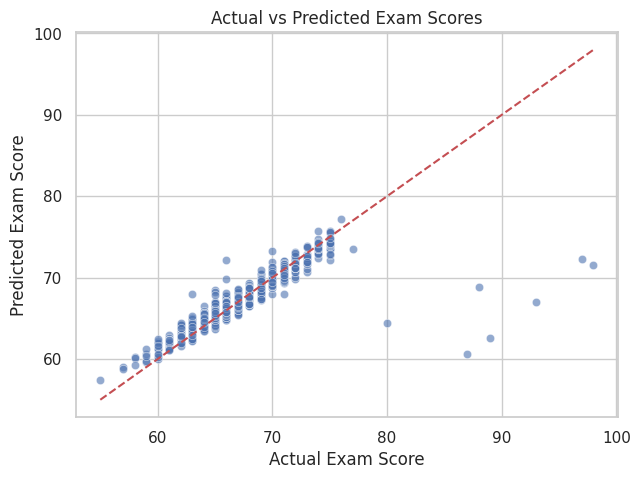

In [29]:
plt.figure(figsize=(7, 5))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)

# Reference line: perfect predictions
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], "r--")

plt.title("Actual vs Predicted Exam Scores")
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")

plt.show()


    Find which features the model relied on

                           Feature  Importance
1                  num__Attendance    0.460201
0               num__Hours_Studied    0.279573
3             num__Previous_Scores    0.048085
4           num__Tutoring_Sessions    0.035960
6   cat__Parental_Involvement_High    0.026023
9    cat__Access_to_Resources_High    0.024651
10    cat__Access_to_Resources_Low    0.018973
7    cat__Parental_Involvement_Low    0.014712
20          cat__Family_Income_Low    0.007815
29    cat__Peer_Influence_Positive    0.007386


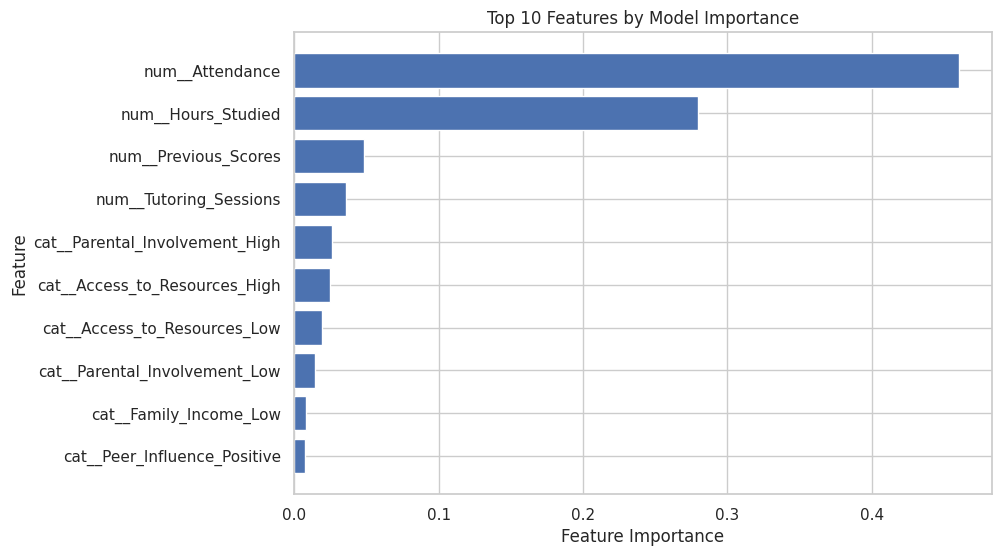

In [30]:

# Extract the trained model and feature names
trained_model = model.named_steps["regressor"]
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(10))

# Plot the ten most important features
top_features = importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Features by Model Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()
